# Exploratory data analysis: HCV laboratory data

This notebook describes the cleaned dataset `hcv_median_imputed.csv` (608 patients) using summary statistics and figures only. It contains no hypothesis tests or models; inferential work is in `stats.ipynb`.

## 1. Configuration and data

Constants are defined once so that every figure uses the same class order and colours. `cat_num` is a label code rather than a measurement, so it is excluded from all numeric summaries.

In [1]:
# Standard library and third-party imports, grouped together.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Settings used throughout: file path, class order and column lists.
DATA_PATH = Path("hcv_median_imputed.csv")
SEED = 42
CLASS_ORDER = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]
NUMERIC_COLS = [
    "Age", "ALB", "ALP", "ALT", "AST", "BIL",
    "CHE", "CHOL", "CREA", "GGT", "PROT",
]
# Strongly right-skewed variables, drawn on a log scale in boxplots.
LOG_COLS = ["ALT", "AST", "BIL", "CREA", "GGT", "ALP"]
# Markers for the pairplot; the first four are log-transformed for display.
PAIR_COLS = ["AST", "ALT", "GGT", "BIL", "CHE", "ALB"]
PAIR_LOG_COLS = ["AST", "ALT", "GGT", "BIL"]
N_COLS = 4

# One fixed colour per category so every figure matches.
PALETTE = dict(zip(
    CLASS_ORDER, ["#4c9f70", "#e8a33d", "#d4622b", "#8c2d3f"]
))

np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# Load the cleaned data and fix the category order so tables and
# plots always list Healthy first and Cirrhosis last.
df = pd.read_csv(DATA_PATH)
df["Category"] = pd.Categorical(
    df["Category"], categories=CLASS_ORDER, ordered=True
)

# Basic structure: number of rows and columns, column types, first rows.
print("Shape:", df.shape)
print()
print(df.dtypes)
df.head()

Shape: (608, 14)

Category    category
Age          float64
Sex           object
ALB          float64
ALP          float64
ALT          float64
AST          float64
BIL          float64
CHE          float64
CHOL         float64
CREA         float64
GGT          float64
PROT         float64
cat_num        int64
dtype: object


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,cat_num
0,Healthy,32.0,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
1,Healthy,32.0,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
2,Healthy,32.0,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
3,Healthy,32.0,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
4,Healthy,32.0,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


## 2. Descriptive statistics

Location and spread are reported for the 11 numeric variables, with skewness and kurtosis (excess) as descriptive measures of shape. Positive skewness indicates a longer right tail. The by-class table gives the median and interquartile range (IQR), which are robust to the outliers present in several enzymes.

In [3]:
# Standard summary table (count, mean, spread, quartiles) for the 11
# measurements, with skewness and kurtosis added as shape measures.
summary = df[NUMERIC_COLS].describe().T
summary["skew"] = df[NUMERIC_COLS].skew()
summary["kurtosis"] = df[NUMERIC_COLS].kurt()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,608.0,47.29,9.99,19.00,39.00,47.00,54.00,77.00,0.25,-0.42
ALB,608.0,41.82,5.40,20.00,39.00,42.00,45.22,82.20,0.29,6.23
ALP,608.0,67.77,24.90,11.30,52.90,66.00,79.03,416.60,4.96,63.64
ALT,608.0,27.59,21.21,0.90,16.40,23.00,32.67,258.00,4.18,30.36
AST,608.0,34.37,32.62,12.00,21.60,25.85,32.80,324.00,5.14,33.13
BIL,608.0,11.47,19.77,1.80,5.30,7.30,11.30,254.00,8.35,82.35
CHE,608.0,8.20,2.17,1.42,6.95,8.27,9.59,16.41,-0.16,1.40
CHOL,608.0,5.38,1.11,1.43,4.63,5.30,6.06,9.67,0.40,0.79
CREA,608.0,81.51,49.72,8.00,68.00,77.00,88.00,1079.10,15.36,283.91
GGT,608.0,38.24,51.95,4.50,15.70,23.25,39.20,650.90,6.11,52.30


In [4]:
# Median and IQR (75th minus 25th percentile) of each variable within
# each category. These ignore extreme values, unlike the mean.
grouped = df.groupby("Category", observed=True)[NUMERIC_COLS]
median = grouped.median()
iqr = grouped.quantile(0.75) - grouped.quantile(0.25)

# Stack the two tables and arrange rows as variable then statistic.
by_class = pd.concat({"median": median, "IQR": iqr}, axis=1)
by_class = by_class.T.swaplevel().sort_index(level=0, sort_remaining=False)
by_class.reindex(NUMERIC_COLS, level=0).round(2)

Category     Healthy  Hepatitis  Fibrosis  Cirrhosis
Age  median    47.00      37.00     51.00      56.00
     IQR       14.00      15.50      9.00      13.00
ALB  median    42.20      43.50     41.00      33.00
     IQR        6.20       4.50      6.00       6.75
ALP  median    66.70      36.95     45.20      67.80
     IQR       24.30      24.77     26.70      43.95
ALT  median    23.10      18.30     34.00       5.65
     IQR       15.10      28.80    103.80      21.60
AST  median    24.80      47.20     70.00      92.90
     IQR        8.70      44.22     63.00      60.45
BIL  median     6.90      13.00     13.00      34.00
     IQR        5.10       8.50      5.00      42.50
CHE  median     8.35       9.51      8.59       3.42
     IQR        2.52       2.74      2.17       3.92
CHOL median     5.38       5.06      4.64       3.92
     IQR        1.43       1.68      0.80       1.26
CREA median    78.00      72.25     71.40      68.50
     IQR       20.00      19.65     13.70      41.45
GGT  median    21.40      45.55     72.20      96.35
     IQR       16.90      56.75     42.30      91.60
PROT median    72.20      73.65     76.10      70.25
     IQR        5.80       6.03      8.60      10.48

## 3. Categorical variables

The outcome is strongly imbalanced, which matters for the choice of evaluation metrics later. Sex is cross-tabulated against Category to show whether the sexes are distributed similarly across diagnoses.

           count  percent
Category                 
Healthy      533     87.7
Hepatitis     24      3.9
Fibrosis      21      3.5
Cirrhosis     30      4.9


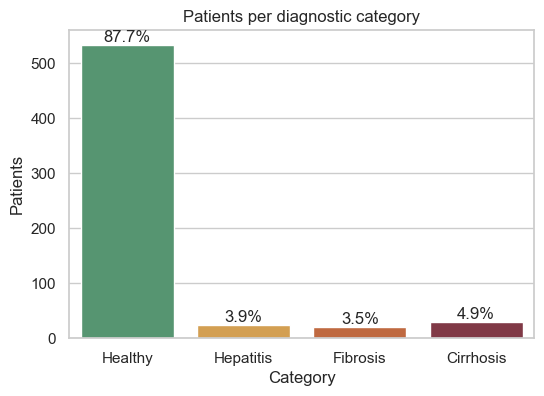

In [5]:
# Number and share of patients in each diagnostic category.
counts = df["Category"].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(df) * 100).round(1),
})
print(class_table)

# Bar chart of the counts, with the percentage written above each bar.
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=counts.index, y=counts.values, hue=counts.index,
    palette=PALETTE, legend=False, ax=ax,
)
for patch, pct in zip(ax.patches, class_table["percent"]):
    x_centre = patch.get_x() + patch.get_width() / 2
    ax.annotate(
        f"{pct}%", (x_centre, patch.get_height()),
        ha="center", va="bottom",
    )
ax.set_title("Patients per diagnostic category")
ax.set_xlabel("Category")
ax.set_ylabel("Patients")
plt.show()

In [6]:
# Overall number and share of male and female patients.
sex_counts = df["Sex"].value_counts()
print(pd.DataFrame({
    "count": sex_counts,
    "percent": (sex_counts / len(df) * 100).round(1),
}))

# Sex within each category, as counts and as a percentage of the row.
sex_by_class = pd.crosstab(df["Category"], df["Sex"])
sex_by_class_pct = pd.crosstab(
    df["Category"], df["Sex"], normalize="index"
) * 100
print()
print("Counts")
print(sex_by_class)
print()
print("Row percentages")
print(sex_by_class_pct.round(1))

     count  percent
Sex                
m      371     61.0
f      237     39.0

Counts
Sex          f    m
Category           
Healthy    215  318
Hepatitis    4   20
Fibrosis     8   13
Cirrhosis   10   20

Row percentages
Sex           f     m
Category             
Healthy    40.3  59.7
Hepatitis  16.7  83.3
Fibrosis   38.1  61.9
Cirrhosis  33.3  66.7


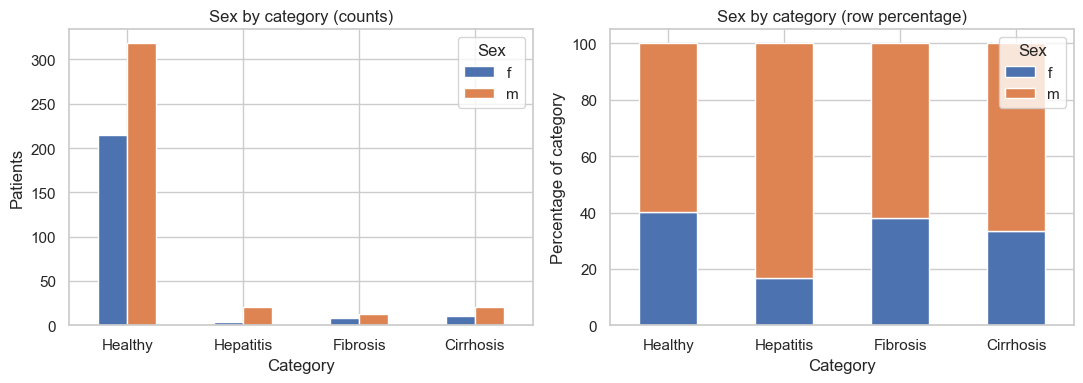

In [7]:
# Left: side-by-side counts. Right: stacked percentages, which make
# the male share comparable between categories of different size.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sex_by_class.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Sex by category (counts)")
axes[0].set_ylabel("Patients")
sex_by_class_pct.plot(kind="bar", stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Sex by category (row percentage)")
axes[1].set_ylabel("Percentage of category")
for ax in axes:
    ax.set_xlabel("Category")
plt.tight_layout()
plt.show()

## 4. Distributions

Histograms with a kernel density estimate show the shape of each variable over all patients. Bin widths follow the Freedman-Diaconis rule (`bins="fd"`), which adapts to the spread and sample size of each variable. A single helper draws any per-variable plot into a grid, and is reused in the next section.

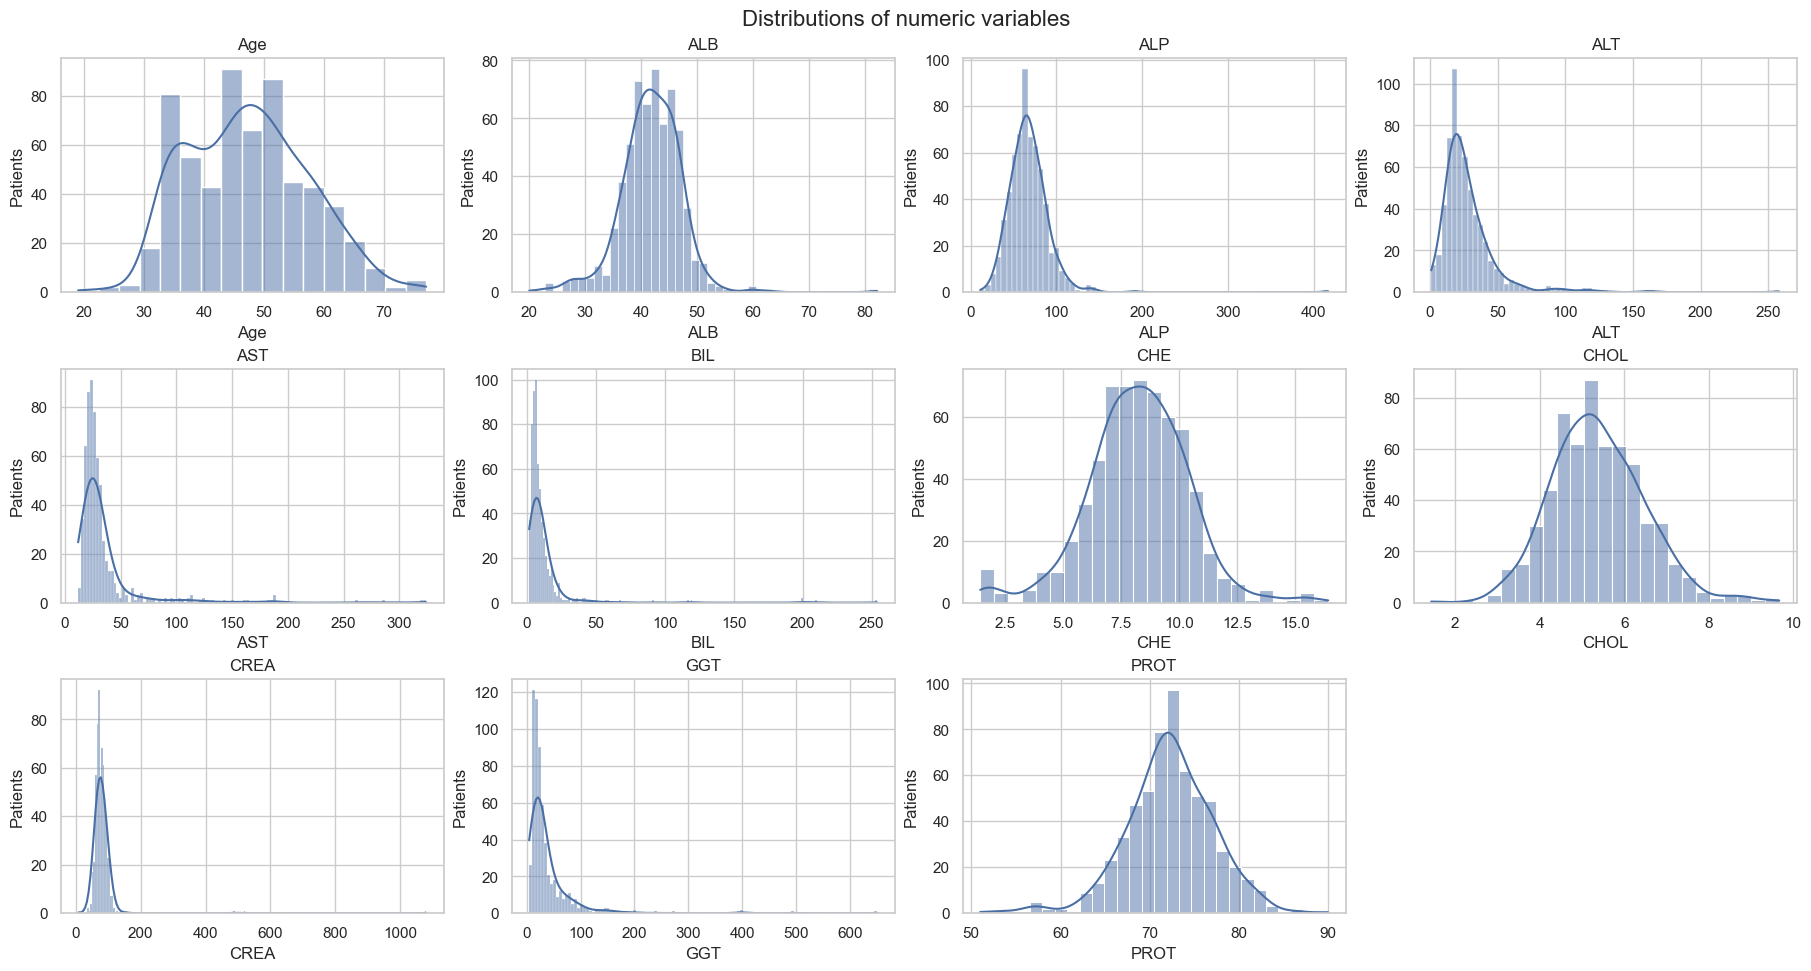

In [8]:
def plot_grid(data, columns, kind, title, n_cols=N_COLS, height=3.2):
    """Draw a histogram or boxplot panel for every column in a grid."""
    # Work out how many rows are needed and create the panels.
    n_rows = int(np.ceil(len(columns) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4.5 * n_cols, height * n_rows),
        constrained_layout=True,
    )

    # Fill one panel per variable.
    for ax, column in zip(axes.flat, columns):
        if kind == "hist":
            # Histogram over all patients with a smooth density curve.
            sns.histplot(
                data[column], bins="fd", kde=True, color="#4a6fa5", ax=ax
            )
            ax.set_xlabel(column)
            ax.set_ylabel("Patients")
        else:
            # One box per category, in class order and fixed colours.
            sns.boxplot(
                data=data, x="Category", y=column, hue="Category",
                order=CLASS_ORDER, hue_order=CLASS_ORDER,
                palette=PALETTE, legend=False, fliersize=2, ax=ax,
            )
            # Skewed variables get a log axis so small boxes stay visible.
            if column in LOG_COLS:
                ax.set_yscale("log")
                ax.set_ylabel(f"{column} (log scale)")
            else:
                ax.set_ylabel(column)
            ax.set_xlabel("Category")
            ax.tick_params(axis="x", rotation=30)
        ax.set_title(column)

    # Hide unused panels in the last row.
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=16)
    return fig


# Histogram grid for all 11 variables.
plot_grid(df, NUMERIC_COLS, "hist", "Distributions of numeric variables")
plt.show()

## 5. Relationships with the target

Boxplots compare each variable across the four categories, in class order. ALT, AST, BIL, CREA, GGT and ALP are plotted on a logarithmic y-axis because they are strongly right-skewed (see the skewness column in section 2) with long upper tails; on a linear axis the boxes of the smaller classes would be compressed against the axis. The remaining variables use a linear axis. Note that the three disease classes contain few patients, so their boxes are based on 21 to 30 observations.

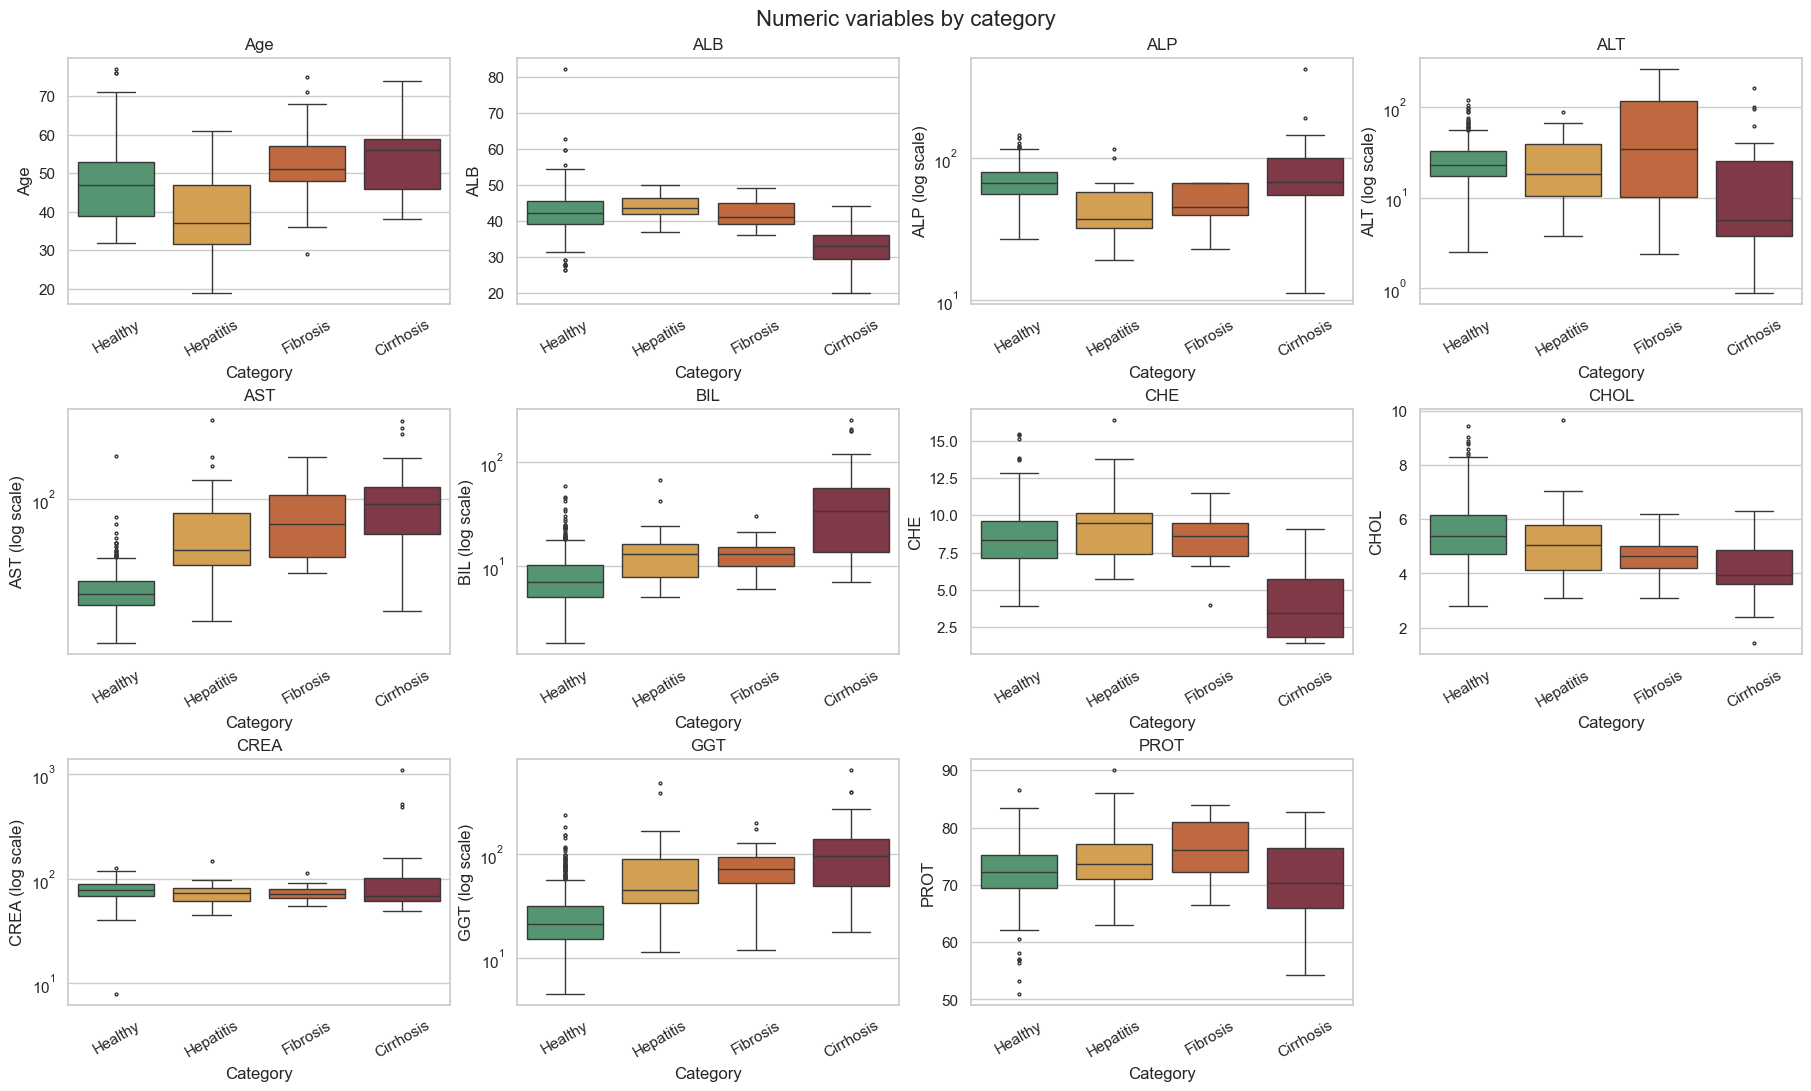

In [9]:
# Boxplot grid of every variable split by category.
plot_grid(
    df, NUMERIC_COLS, "box", "Numeric variables by category", height=3.6
)
plt.show()

## 6. Relationships between variables

Pearson correlation measures linear association and is sensitive to the outliers noted above. Spearman correlation uses ranks, so it captures monotonic association and is more robust. Showing both indicates how much the linear coefficients depend on extreme values. Only the lower triangle is drawn because the matrix is symmetric.

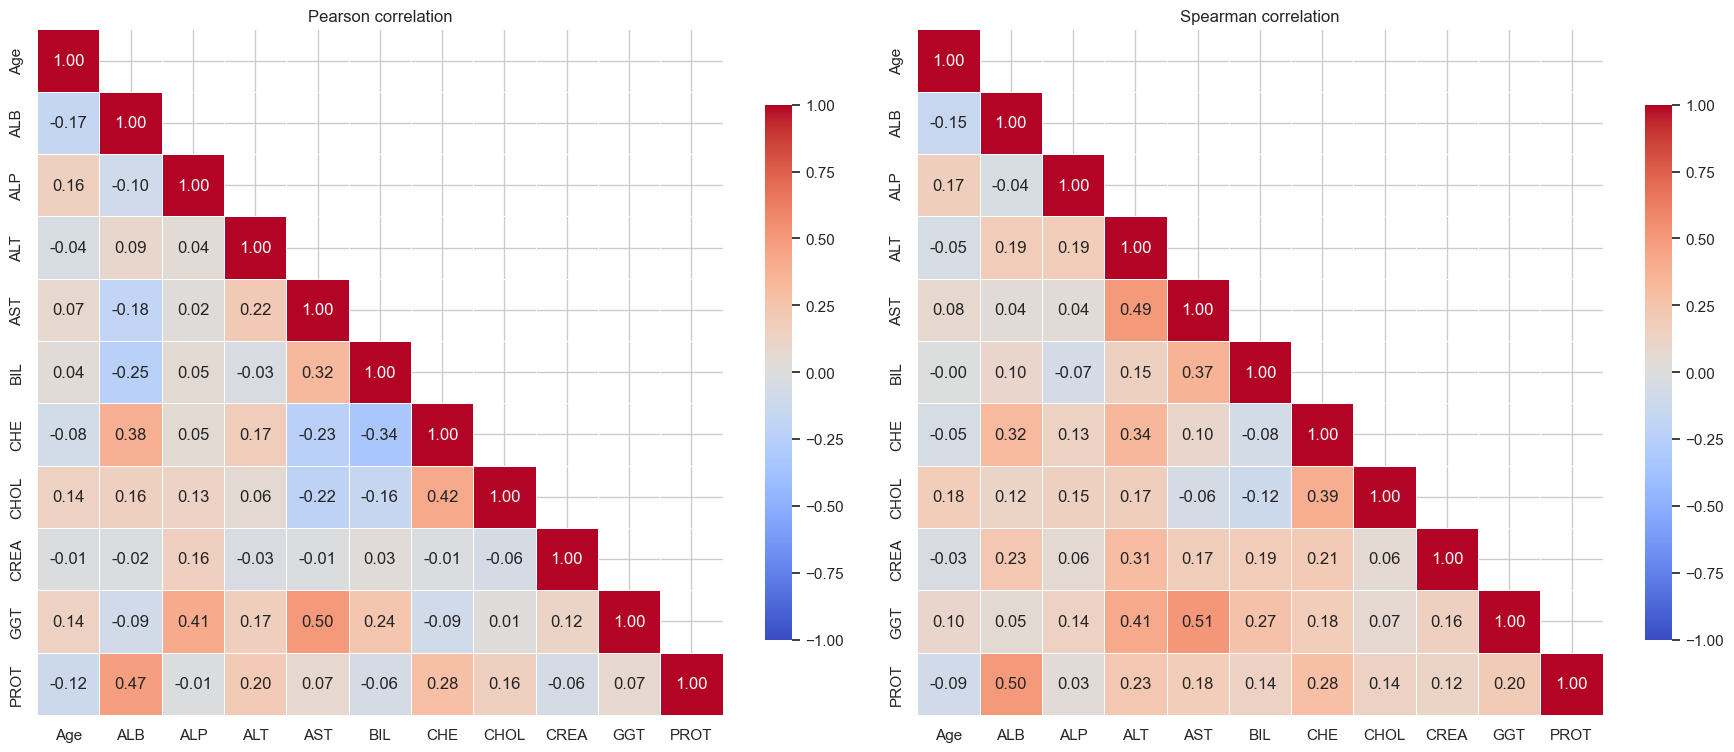

In [10]:
# Pearson (linear) and Spearman (rank-based) correlation matrices.
pearson = df[NUMERIC_COLS].corr(method="pearson")
spearman = df[NUMERIC_COLS].corr(method="spearman")

# Hide the upper triangle: the matrix is symmetric, so it repeats.
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)

# Draw both heatmaps side by side with the same colour scale.
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, corr, name in zip(axes, [pearson, spearman],
                          ["Pearson", "Spearman"]):
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
        vmin=-1, vmax=1, square=True, linewidths=0.5,
        cbar_kws={"shrink": 0.7}, ax=ax,
    )
    ax.set_title(f"{name} correlation")
plt.tight_layout()
plt.show()

In [11]:
# List the five strongest pairs (ignoring the diagonal) for each method.
for name, corr in [("Pearson", pearson), ("Spearman", spearman)]:
    # Keep each pair once by taking only the lower triangle.
    lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
    pairs = lower.stack()
    order = pairs.abs().sort_values(ascending=False).index
    print(f"Strongest {name} pairs")
    print(pairs.reindex(order)[:5].round(2))
    print()

Strongest Pearson pairs
GGT   AST    0.50
PROT  ALB    0.47
CHOL  CHE    0.42
GGT   ALP    0.41
CHE   ALB    0.38
dtype: float64

Strongest Spearman pairs
GGT   AST    0.51
PROT  ALB    0.50
AST   ALT    0.49
GGT   ALT    0.41
CHOL  CHE    0.39
dtype: float64



A pairplot of six clinically relevant liver markers shows the joint structure by category. AST, ALT, GGT and BIL are strongly right-skewed, so they are shown as log10 values (labelled `log10`) to stop a few extreme patients compressing the rest of the points. CHE and ALB stay on their original scale. This transformation is for display only. Only the lower triangle is drawn, with kernel density estimates on the diagonal.

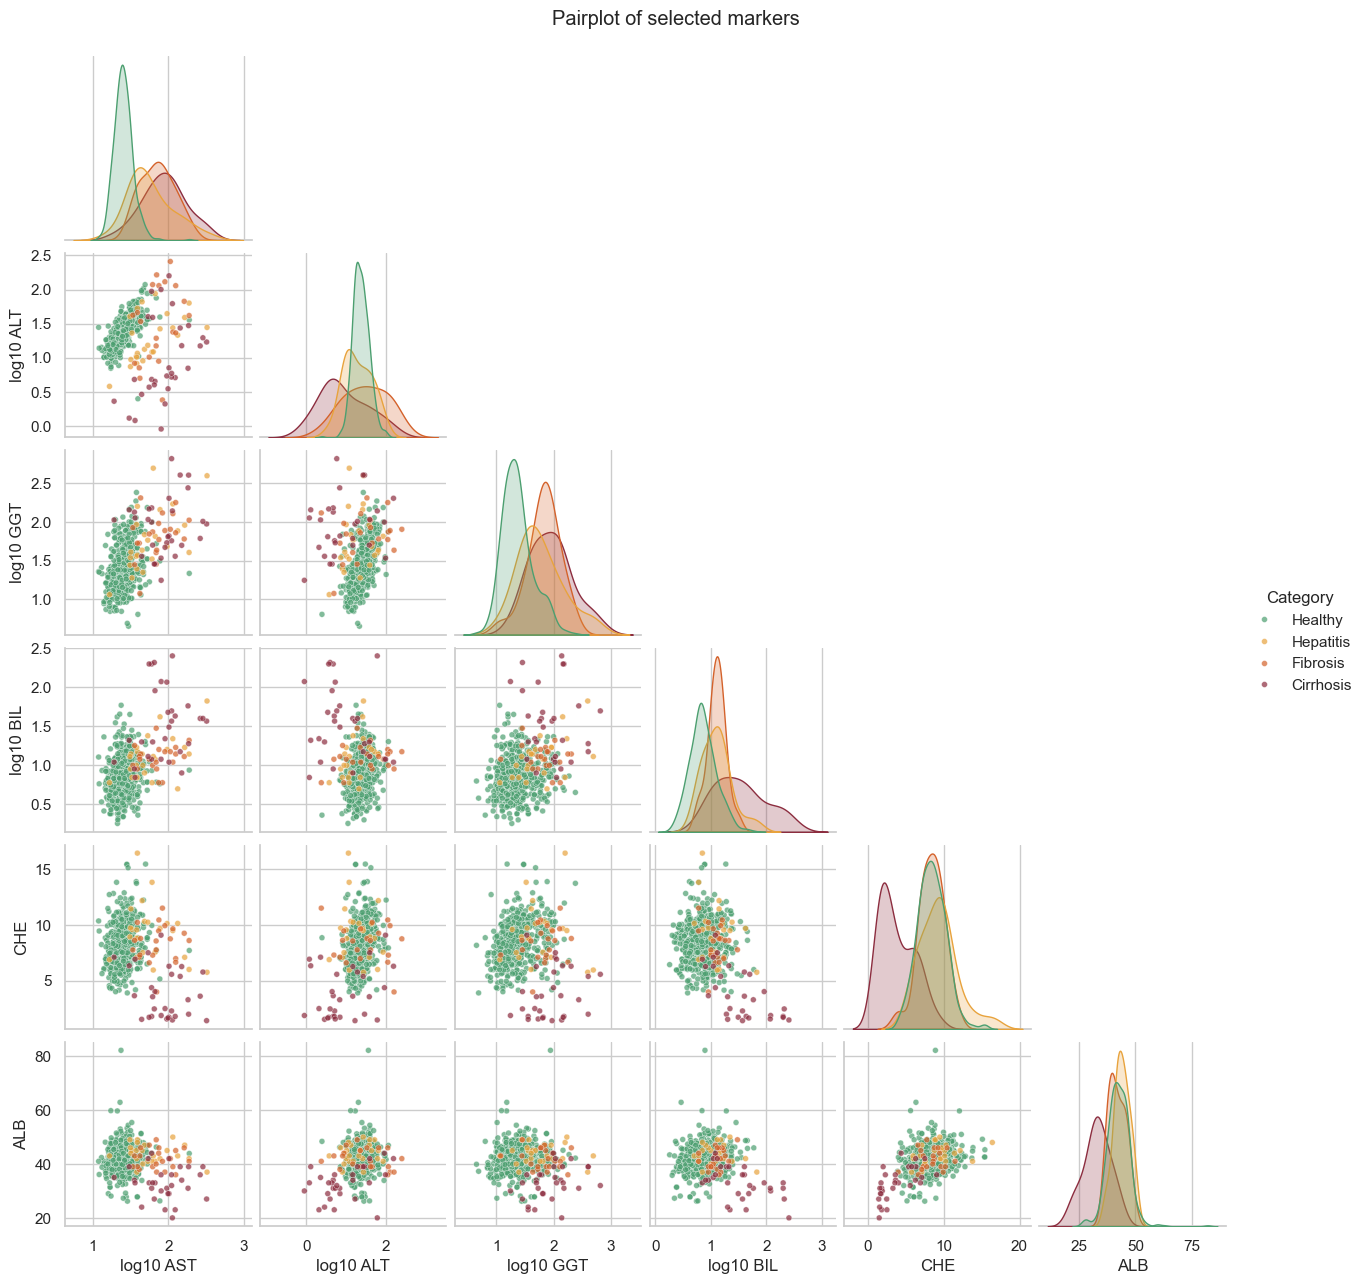

In [12]:
# Copy the data and replace the skewed markers by their log10 values,
# renaming the columns so the axis labels say they are logged.
pair_data = df[PAIR_COLS + ["Category"]].copy()
for column in PAIR_LOG_COLS:
    pair_data[f"log10 {column}"] = np.log10(pair_data[column])
    pair_data = pair_data.drop(columns=column)

# Keep the original marker order, using the renamed columns.
pair_vars = [
    f"log10 {c}" if c in PAIR_LOG_COLS else c for c in PAIR_COLS
]

# Scatter plots by category, with density curves on the diagonal.
pair_grid = sns.pairplot(
    pair_data, vars=pair_vars, hue="Category", hue_order=CLASS_ORDER,
    palette=PALETTE, corner=True, diag_kind="kde",
    plot_kws={"s": 18, "alpha": 0.7}, diag_kws={"common_norm": False},
    height=2.1,
)
pair_grid.figure.suptitle("Pairplot of selected markers", y=1.02)
plt.show()

## 7. Summary of observations

These observations are descriptive and make no inferential claim.

- **Class imbalance.** Healthy patients make up 533 of 608 (87.7%); Hepatitis, Fibrosis and Cirrhosis have 24 (3.9%), 21 (3.5%) and 30 (4.9%).
- **Sex.** 371 patients are male (61.0%). The male share is 59.7% in Healthy and 83.3% in Hepatitis (20 of 24), with 61.9% in Fibrosis and 66.7% in Cirrhosis; the disease groups are small, so these percentages rest on few patients.
- **Skewness.** CREA (skewness 15.36), BIL (8.35), GGT (6.11), AST (5.14), ALP (4.96) and ALT (4.18) are strongly right-skewed with very high excess kurtosis (CREA 283.91). Age (0.25), ALB (0.29), CHE (-0.16), CHOL (0.40) and PROT (-0.40) are close to symmetric by comparison.
- **Differences by class.** Median AST rises from 24.80 (Healthy) to 47.20, 70.00 and 92.90 (Cirrhosis); GGT from 21.40 to 45.55, 72.20 and 96.35; BIL from 6.90 to 34.00 in Cirrhosis. Median CHE (3.42) and ALB (33.00) are lowest in Cirrhosis, against 8.35 and 42.20 in Healthy. Median ALT does not follow a monotonic pattern (23.10, 18.30, 34.00, 5.65). Median CREA varies little between classes (68.50 to 78.00).
- **Correlations.** Associations are modest. The strongest Pearson pair is GGT-AST (0.50), followed by PROT-ALB (0.47) and CHOL-CHE (0.42). Spearman gives similar values (GGT-AST 0.51, PROT-ALB 0.50), with AST-ALT (0.49) entering the top three.
